In [14]:
import pandas as pd

df = pd.read_csv('emissions.csv')

df['year'] = df['year'].astype(int)
df['value'] = df['value'].astype(float)
df['sector-name'] = df['sector-name'].str.replace(' carbon dioxide emissions', '', regex=False)

df.head(10)


,year,state-name,sector-name,fuel-name,value
0,1970,Alabama,Industrial,Coal,26.721507
1,1970,Alabama,Industrial,Petroleum,3.577779
2,1970,Alabama,Industrial,Natural Gas,8.944097
3,1970,Alabama,Industrial,All Fuels,39.243383
4,1970,Alabama,Total from all sectors,All Fuels,102.646851
5,1970,Alabama,Total from all sectors,Coal,63.266935
6,1970,Alabama,Total from all sectors,Petroleum,23.474612
7,1970,Alabama,Total from all sectors,Natural Gas,15.905305
8,1970,Alabama,Residential,Coal,0.163635
9,1970,Alabama,Residential,Petroleum,1.123947


## Chow Test

### Introductory data exploration


Notes: (from Luis) I wanted to do a test with yearly data since I had spent some hours doing analysis of emissions by year, so I researched some options and found the Chow Test was somewhat related to what I did. I only realized this was not part of the course until after it was mostly complete, so I decided to include it anwyays. 

Additionally, the change in slope (what we are testing) is obvious when observing the graph, but I think it's the process that matters.

To begin, let's take a look at the total emissions by year:

[]

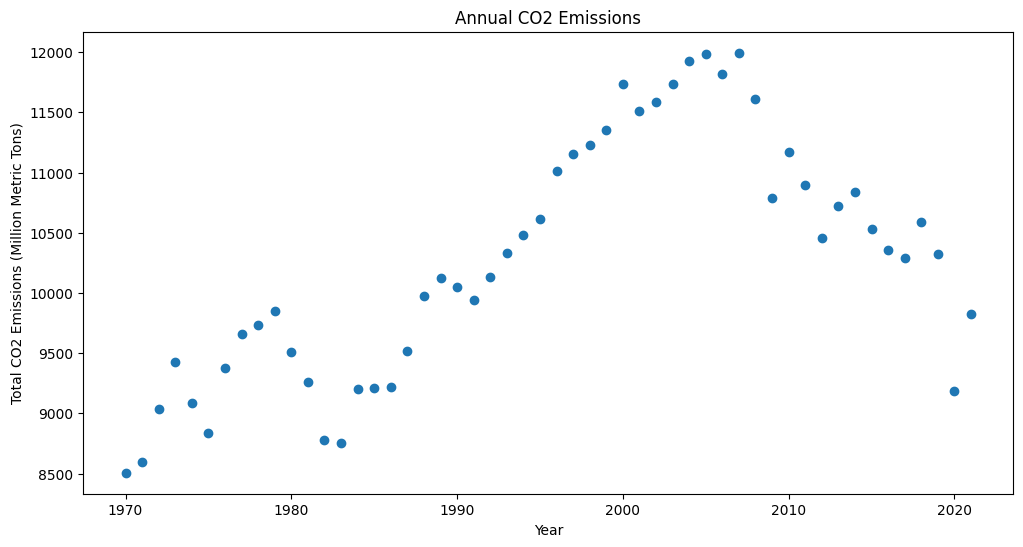

In [15]:
import matplotlib.pyplot as plt

totals = df[(df["sector-name"] == "Total from all sectors") & (df["fuel-name"] == "All Fuels")].copy()
annual_emissions = (totals.groupby("year")["value"].sum().reset_index().rename(columns={"value": "total_co2"}))
#print(annual_emissions.head())

# plot annual emissions data
plt.figure(figsize=(12,6))

x = annual_emissions['year']
y = annual_emissions['total_co2']

plt.scatter(x, y)

plt.title('Annual CO2 Emissions')
plt.xlabel('Year')
plt.ylabel('Total CO2 Emissions (Million Metric Tons)')

plt.plot()



We observe that there is a peak at 2005, and that from 1982 to 2005 there seems to be a steady incline and from 2005 onwards a steady decline. We want to know if this change in slope (at 2005) is statistically significant, and if so by how much the slope shifts, so we perform a Chow Test for structural break:

HO: The change in slope at 2005 is not statistically significant 
HA: The change in slope at 2005 is statistically significant

We will only include years after 1981, since that is where the main upwards slope begins.

### Hypothesis testing and graphing

Results:
1982–2005 Slope: +143.82 MMT/year
2006–2021 Slope: -133.61 MMT/year
Slope Shift: -277.43 MMT/year
p-value: 2.4985e-19


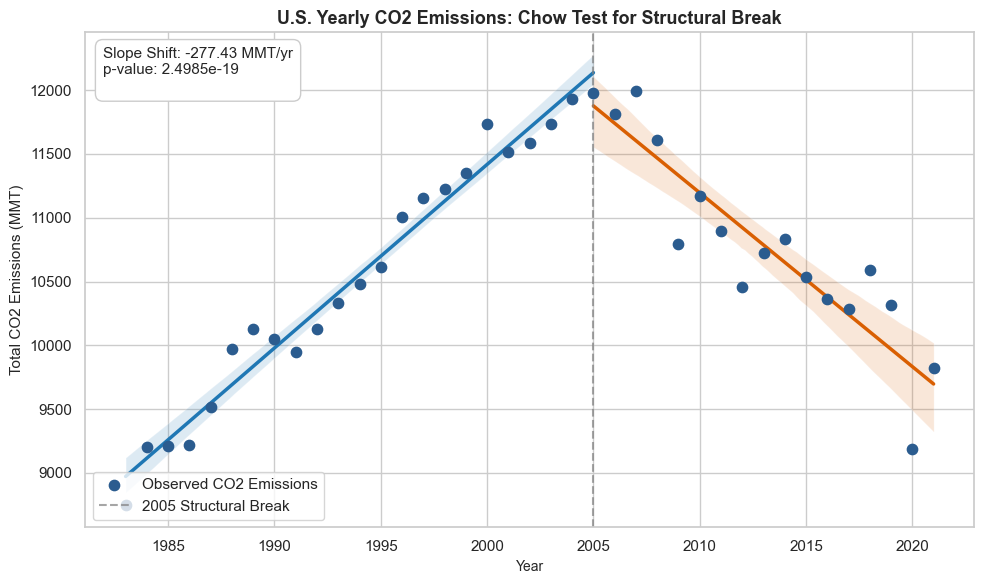

In [42]:
import seaborn as sns
import statsmodels.formula.api as smf

# years after 1981
annual_emissions = annual_emissions[annual_emissions["year"] > 1981].reset_index(drop=True)

# the chow test uses a dummy variable (is_post_2005), and honestly I'm still not entirely sure why, but it works lol
annual_emissions["year_centered"] = annual_emissions["year"] - 2005
annual_emissions["is_post_2005"] = (annual_emissions["year"] > 2005).astype(int) 

# fit interaction model
chow_model = smf.ols("total_co2 ~ year_centered * is_post_2005", data=annual_emissions).fit()

# get params
slope_pre_2005 = chow_model.params["year_centered"]
slope_shift = chow_model.params["year_centered:is_post_2005"]
slope_post_2005 = slope_pre_2005 + slope_shift

p_val = chow_model.pvalues["year_centered:is_post_2005"]

print("Results:")
print(f"1982–2005 Slope: {slope_pre_2005:+.2f} MMT/year")
print(f"2006–2021 Slope: {slope_post_2005:+.2f} MMT/year")
print(f"Slope Shift: {slope_shift:+.2f} MMT/year")
print(f"p-value: {p_val:.4e}")

# plotting (using seaborn to help with the linear regression viz)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(annual_emissions["year"], annual_emissions["total_co2"], color="#2b5c8f", s=55, zorder=3, label="Observed CO2 Emissions")

upwards = annual_emissions[annual_emissions["year"] <= 2005]
downwards = annual_emissions[annual_emissions["year"] >= 2005]

# linear regression for upwards/downwards slope sections
sns.regplot(data=upwards, x="year", y="total_co2", ax=ax, color="#1f77b4", scatter=False, line_kws={"linewidth": 2.5, "label": f"1983–2005 Trend ({slope_pre_2005:+.1f} MMT/yr)"})
sns.regplot(data=downwards, x="year", y="total_co2", ax=ax, color="#d95f02", scatter=False, line_kws={"linewidth": 2.5, "label": f"2006–2021 Trend ({slope_post_2005:+.1f} MMT/yr)"})

# structural break line
ax.axvline(2005, color="gray", linestyle="--", linewidth=1.5, alpha=0.7, label="2005 Structural Break")

# textbox
stats_text = (f"Slope Shift: {slope_shift:+.2f} MMT/yr\n" f"p-value: {p_val:.4e}\n")
ax.text(0.02, 0.97, stats_text, transform=ax.transAxes, fontsize=11, verticalalignment="top", bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc"))

ax.set_title("U.S. Yearly CO2 Emissions: Chow Test for Structural Break", fontsize=13, fontweight="bold")
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Total CO2 Emissions (MMT)", fontsize=11)
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

### Conclusions



We see from the results of the test the p-value is increadibly small (~2.5e-19), which means that the "structural break," or the change in slope at 2005 observable in the original graph and represented by the two linear regression models (blue and orange lines), is indeed statistically significant. With this in mind, we successfully reject HO.

The Chow Test also tells us how much the slope has shifted; The results show a downward shift of ~277 MMT/year. Assuming we knew that emissions policies were enacted in 2005, we could use this to tell whether they were successfuly or not.